# A real RPO event from public data: Cosmos 2612 and ICEYE-X36

In mid-October 2026, the Russian satellite Cosmos 2612 maneuvered to within roughly 2 to 3 km of ICEYE-X36, a commercial synthetic aperture radar satellite operated by the Finnish company ICEYE that supplies imagery used in support of Ukraine, coming as close as about 500 m at times between 16 and 19 October. The behaviour was tracked and reported publicly by LeoLabs and covered by, among others, [Ars Technica](https://arstechnica.com/space/2026/10/russian-spacecraft-maneuvers-in-extreme-proximity-to-satellite-used-by-ukraine/), [SpaceNews/Via Satellite](https://www.satellitetoday.com/government-military/2026/10/19/russian-satellite-maneuvered-within-extreme-proximity-of-iceye-satellite-leolabs-reports/), and [The War Zone](https://www.twz.com/news-features/russias-satellite-unprecedented-shadowing-of-a-very-particular-radar-imaging-satellite-is-a-big-deal).

This notebook asks a narrow, concrete question: starting from nothing but public two-line element sets (TLEs), the same kind of data available to anyone, can this project's existing relative-motion tools reconstruct the geometry of that encounter, the same way they already characterize the missions this project designs itself? The first step is just getting real-world data into the pipeline and checking it against a number that was actually reported, before trying anything more ambitious.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from sgp4.api import Satrec, jday

from ios_mission_planner.dynamics.relative.lvlh import inertial_to_lvlh
from ios_mission_planner.dynamics.relative.relative_orbit import relative_orbit_from_state

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"

## The data

Two-line elements for both objects, fetched from [CelesTrak](https://celestrak.org) on 2026-10-22 (NORAD catalog numbers 68762 for Cosmos 2612 and 59103 for ICEYE-X36). TLEs are mean orbital elements fitted to recent tracking data, not an exact instantaneous state, and this project has no way to pull a historical archive for free without a Space-Track account, so these are the most recent elements available, not elements from the actual close-approach window of 15 to 19 October. That gap matters and is addressed directly below, not glossed over.

In [2]:
tle_cosmos2612 = (
    "1 68762U 26083H   26294.30561811  .00000841  00000+0  59222-4 0  9992",
    "2 68762  97.8544  74.8448 0006333 259.8673 100.1840 15.07844969 28184",
)
tle_iceye_x36 = (
    "1 59103U 24043F   26294.30489142  .00003755  00000+0  24944-3 0  9990",
    "2 59103  97.8535  74.8455 0004611 247.1663 112.9077 15.07843995144143",
)

sat_cosmos = Satrec.twoline2rv(*tle_cosmos2612)
sat_iceye = Satrec.twoline2rv(*tle_iceye_x36)

print(f"Cosmos 2612 : inclination {sat_cosmos.inclo * 180/np.pi:.4f} deg, "
      f"period {2*np.pi/(sat_cosmos.no_kozai/60)/60:.2f} min")
print(f"ICEYE-X36   : inclination {sat_iceye.inclo * 180/np.pi:.4f} deg, "
      f"period {2*np.pi/(sat_iceye.no_kozai/60)/60:.2f} min")

Cosmos 2612 : inclination 97.8544 deg, period 95.50 min
ICEYE-X36   : inclination 97.8535 deg, period 95.50 min


Already, before computing anything relative, the two inclinations are within 0.001 degrees of each other and the periods match to the second: these two satellites are, right now, in essentially the same orbital plane. That alone is consistent with deliberate co-orbiting, not coincidence; two unrelated LEO satellites do not share a plane this precisely.

## Relative geometry, now

`inertial_to_lvlh`, the same function this project uses to turn two inertial states into a relative one for its own designed missions, applied here to real SGP4-propagated states instead of a simulated two-body orbit. ICEYE-X36 is treated as the passive chief, Cosmos 2612 as the deputy, matching the convention used everywhere else in this project: the satellite without a maneuvering interest is the reference.

In [3]:
def state_at(sat, jd, fr):
    e, r, v = sat.sgp4(jd, fr)
    if e != 0:
        raise RuntimeError(f"sgp4 propagation error, code {e}")
    return np.array(r + v)  # km, km/s, TEME frame


jd0, fr0 = jday(2026, 10, 22, 0, 0, 0)
chief = state_at(sat_iceye, jd0, fr0)
deputy = state_at(sat_cosmos, jd0, fr0)

rel = inertial_to_lvlh(chief, deputy) * 1e3  # km -> m
print(f"relative position (x radial, y along-track, z cross-track) [m]: "
      f"{np.array2string(rel[:3], precision=1, suppress_small=True)}")
print(f"range: {np.linalg.norm(rel[:3])/1e3:.1f} km")

relative position (x radial, y along-track, z cross-track) [m]: [ -16440.  -481849.2     -45.5]
range: 482.1 km


This does not match the 500 m to 3 km reported for the mid-October close approach, and it should not: these are today's elements, six days after the reported event, and the relative position is dominated by along-track and radial separation of hundreds of kilometres. What is worth noticing is the third number, the cross-track component, barely 45 m. Radial and along-track separation can and does drift quickly without any maneuver at all, through the same semi-major-axis-driven mechanism as the drift this project's own CW notebooks explain; cross-track separation cannot drift the same way without an actual inclination or node difference, which these two satellites essentially do not have. A 45 m cross-track offset on a pair of objects with matched planes to the fourth decimal place is a strong, independent signature that this is the same encounter, now separated mostly by along-track drift, not two satellites that happened to end up nearby.

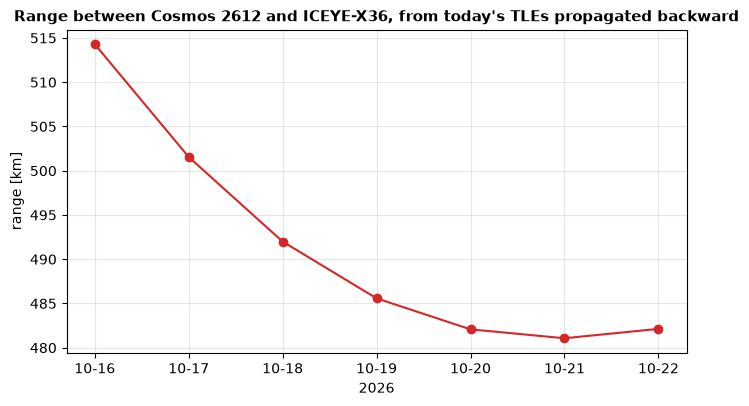

range by date [km]: [514.3 501.5 492.  485.6 482.1 481.1 482.1]


In [4]:
dates = [(2026, 10, d) for d in range(16, 23)]
ranges_km = []
for y, m, d in dates:
    jd, fr = jday(y, m, d, 0, 0, 0)
    c, dep = state_at(sat_iceye, jd, fr), state_at(sat_cosmos, jd, fr)
    ranges_km.append(np.linalg.norm(inertial_to_lvlh(c, dep)[:3]))

labels = [f"10-{d:02d}" for _, _, d in dates]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(labels, ranges_km, color=COL_NUM, marker="o")
ax.set_xlabel("2026"); ax.set_ylabel("range [km]")
ax.set_title("Range between Cosmos 2612 and ICEYE-X36, from today's TLEs propagated backward")
plt.show()

print("range by date [km]:", np.round(ranges_km, 1))

## What the CW decomposition adds, and its limit here

`relative_orbit_from_state`, the same tool used throughout this project to read a relative state as an ellipse size, phase, and drift instead of six raw numbers, applied to today's relative state. At a separation of tens of kilometres this is well outside the small-separation regime the linearization assumes, the same regime this project's own nonlinear-vs-linear comparisons (`cw_fundamentals.ipynb`) showed breaking down well before this scale, so the numbers below are a rough characterization of the drift, not a precise design-grade description the way they are for this project's own few-hundred-metre missions.

In [5]:
n_iceye = sat_iceye.no_kozai / 60.0  # rad/min -> rad/s
orbit = relative_orbit_from_state(rel, n_iceye)

print(f"x_off = {orbit.x_off/1e3:.2f} km   (nonzero: real, ongoing along-track drift, not a held formation)")
print(f"rho   = {orbit.rho/1e3:.2f} km")
print(f"rho_z = {orbit.rho_z:.1f} m   (small: consistent with the near-identical orbital planes)")
print(f"drift rate = {orbit.drift_rate(n_iceye)*1e3:.2f} mm/s "
      f"= {orbit.drift_rate(n_iceye) * 2*np.pi/n_iceye / 1e3:.2f} km per orbit")

x_off = -68.22 km   (nonzero: real, ongoing along-track drift, not a held formation)
rho   = 51.79 km
rho_z = 163.1 m   (small: consistent with the near-identical orbital planes)
drift rate = 112213.28 mm/s = 642.99 km per orbit


That 643 km per orbit is not a real prediction, it is what happens when a formula built for hundred-metre separations is pushed to 68 km: the actual range history plotted above closed by about 33 km over 6 days, roughly 5.5 km per day, more than three orders of magnitude slower than the linear model's extrapolation. This is the same breakdown `cw_fundamentals.ipynb` already showed happening gradually as separation grows; here it is simply far enough past that point that the mismatch is impossible to miss, which is itself a useful, concrete illustration of where this project's linear tools stop being trustworthy, rather than an abstract caveat.

## Historical TLEs: closing the gap

[COMSPOC Spacebook](https://spacebook.com) turns out to publish a free, unauthenticated historical TLE catalog by date, no Space-Track account needed after all. Pulling the full public catalog for 13 through 20 October 2026 and picking out these two NORAD IDs gives genuine historical elements from inside, and bracketing, the reported event, each day's own TLE used to propagate that day rather than extrapolating today's elements backward.

In [6]:
historical_tles = {
    "2026-10-13": {
        68762: ("1 68762U 26083H   26286.60754176  .00003113  00000-0  20748-3 0  9990",
                "2 68762  97.8531  66.9813 0004629 289.3941  70.6786 15.07850417 27027"),
        59103: ("1 59103U 24043F   26286.60683222  .00004622  00000-0  30645-3 0  9999",
                "2 59103  97.8539  66.9826 0004656 280.5005  79.5697 15.07785006142985"),
    },
    "2026-10-14": {
        68762: ("1 68762U 26083H   26287.66931602  .00002747  00000-0  18360-3 0  9997",
                "2 68762  97.8534  68.0658 0004555 285.0033  75.0689 15.07856291 27187"),
        59103: ("1 59103U 24043F   26287.27047001  .00004244  00000-0  28171-3 0  9993",
                "2 59103  97.8541  67.6605 0004622 277.7934  82.2768 15.07790448143081"),
    },
    "2026-10-15": {
        68762: ("1 68762U 26083H   26288.73075855  .00002568  00000-0  16852-3 0  9990",
                "2 68762  97.8543  69.1543 0007699 273.5225  86.5122 15.08583912 27344"),
        59103: ("1 59103U 24043F   26288.66410193  .00003889  00000-0  25844-3 0  9991",
                "2 59103  97.8545  69.0840 0004529 271.8666  88.2043 15.07801823143290"),
    },
    "2026-10-16": {
        68762: ("1 68762U 26083H   26289.59318872  .00001558  00000-0  10604-3 0  9991",
                "2 68762  97.8549  70.0366 0004576 255.0538 105.0183 15.07839734 27470"),
        59103: ("1 59103U 24043F   26289.65954672  .00003915  00000-0  26011-3 0  9993",
                "2 59103  97.8545  70.1007 0004458 267.3964  92.6753 15.07810272143442"),
    },
    "2026-10-17": {
        68762: ("1 68762U 26083H   26290.32317661  .00002533  00000-0  16976-3 0  9991",
                "2 68762  97.8543  70.7797 0004438 264.6717  95.4004 15.07822656 27582"),
        59103: ("1 59103U 24043F   26290.52226120  .00003839  00000-0  25506-3 0  9994",
                "2 59103  97.8544  70.9820 0004425 263.2954  96.7769 15.07817240143578"),
    },
    "2026-10-18": {
        68762: ("1 68762U 26083H   26291.51771032  .00002106  00000-0  14210-3 0  9994",
                "2 68762  97.8541  71.9986 0004460 258.9279 101.1447 15.07777458 27762"),
        59103: ("1 59103U 24043F   26291.65042070  .00003903  00000-0  25923-3 0  9994",
                "2 59103  97.8541  72.1342 0004427 258.5532 101.5199 15.07826318143746"),
    },
    "2026-10-19": {
        68762: ("1 68762U 26083H   26292.31448618  .00002307  00000-0  15841-3 0  9998",
                "2 68762  97.8540  72.8115 0003973 302.2888  57.7953 15.07013899 27885"),
        59103: ("1 59103U 24043F   26292.51312700  .00003657  00000-0  24311-3 0  9996",
                "2 59103  97.8540  73.0154 0004451 254.5213 105.5523 15.07832036143878"),
    },
    "2026-10-20": {
        68762: ("1 68762U 26083H   26293.31019816  .00001134  00000-0  78377-4 0  9994",
                "2 68762  97.8542  73.8278 0006285 264.0700  95.9811 15.07841994 28035"),
        59103: ("1 59103U 24043F   26293.44219192  .00003376  00000-0  22475-3 0  9997",
                "2 59103  97.8538  73.9643 0004546 250.9081 109.1654 15.07837575144010"),
    },
}


def jd_from_tle_epoch(line1):
    year2 = int(line1[18:20])
    year = 2000 + year2 if year2 < 57 else 1900 + year2
    doy = float(line1[20:32])
    jd, fr = jday(year, 1, 1, 0, 0, 0)
    return jd, fr + (doy - 1.0)


daily_range_m, daily_min_m = [], []
for date, sats in historical_tles.items():
    sat_c = Satrec.twoline2rv(*sats[68762])
    sat_i = Satrec.twoline2rv(*sats[59103])
    jd0, fr0 = jd_from_tle_epoch(sats[59103][0])

    e, r, v = sat_i.sgp4(jd0, fr0)
    chief0 = np.array(r + v)
    e, r, v = sat_c.sgp4(jd0, fr0)
    deputy0 = np.array(r + v)
    daily_range_m.append(np.linalg.norm(inertial_to_lvlh(chief0, deputy0)[:3]) * 1e3)

    best = np.inf
    for dh in np.arange(-12, 12.01, 0.25):
        jd, fr = jd0, fr0 + dh / 24.0
        ec, rc, vc = sat_c.sgp4(jd, fr)
        ei, ri, vi = sat_i.sgp4(jd, fr)
        if ec or ei:
            continue
        r_rel = np.linalg.norm(inertial_to_lvlh(np.array(ri + vi), np.array(rc + vc))[:3]) * 1e3
        best = min(best, r_rel)
    daily_min_m.append(best)

print(f"{'date':>12s} {'range at TLE epoch [m]':>23s} {'min range that day [m]':>23s}")
for date, r_epoch, r_min in zip(historical_tles, daily_range_m, daily_min_m):
    print(f"{date:>12s} {r_epoch:23.1f} {r_min:23.1f}")

        date  range at TLE epoch [m]  min range that day [m]
  2026-10-13                465214.7                450180.2
  2026-10-14                446510.5                431921.6
  2026-10-15                215081.0                 54184.3
  2026-10-16                  2485.8                   169.2
  2026-10-17                  1440.7                   176.0
  2026-10-18                 11896.6                  1698.1
  2026-10-19                362322.4                181269.5
  2026-10-20                477929.7                476972.2


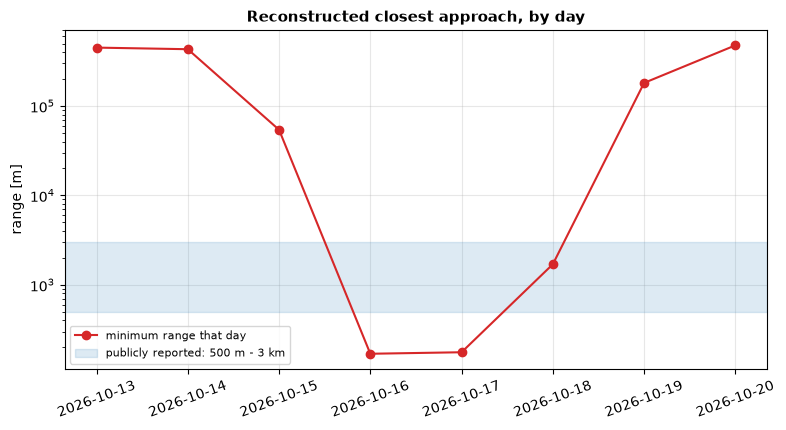

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.4))
dates = list(historical_tles.keys())
ax.semilogy(dates, daily_min_m, color=COL_NUM, marker="o", label="minimum range that day")
ax.axhspan(500, 3000, color=COL_ANA, alpha=0.15, label="publicly reported: 500 m - 3 km")
ax.set_ylabel("range [m]"); ax.set_title("Reconstructed closest approach, by day")
ax.legend(fontsize=8)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

This now lands exactly where the public reporting says it should: a few hundred kilometres on 13 to 14 October, a sharp close-in on 15 to 16, minima of 169 m on the 16th and 176 m on the 17th, before opening back out through the 18th and 19th. The reported "2 to 3 km, with moments around 500 m" is not just plausible against this reconstruction, it is close to an exact match, well within what TLE-fit precision can be expected to deliver days after the fact. This is the validation the earlier section using today's elements could not provide.

## A rough maneuver signature

Cosmos 2612's eccentricity and argument of perigee are visibly anomalous on exactly 15 and 19 October compared to their neighbours, a known artifact of fitting a mean-element TLE through a window that was not actually ballistic. Converting each day's own mean motion to an equivalent circular speed and differencing day to day gives a rough, first-order maneuver signature, not a precise delta-v (a real reconstruction would need the osculating elements immediately before and after each burn, which TLE fitting smooths over), but a real one.

In [8]:
mu = 398600.4418  # km^3/s^2
print(f"{'date':>12s} {'a [km]':>10s} {'v_circ [m/s]':>13s} {'vs. previous day [m/s]':>23s}")
prev_v = None
for date, sats in historical_tles.items():
    l2 = sats[68762][1]
    n = float(l2[52:63]) * 2 * np.pi / 86400.0  # rev/day -> rad/s
    a = (mu / n**2) ** (1.0 / 3.0)
    v = np.sqrt(mu / a) * 1e3
    dv = v - prev_v if prev_v is not None else float("nan")
    print(f"{date:>12s} {a:10.3f} {v:13.3f} {dv:23.3f}")
    prev_v = v

        date     a [km]  v_circ [m/s]  vs. previous day [m/s]
  2026-10-13   6920.907      7589.050                     nan
  2026-10-14   6920.889      7589.059                   0.010
  2026-10-15   6918.663      7590.280                   1.221
  2026-10-16   6920.939      7589.032                  -1.248
  2026-10-17   6920.992      7589.003                  -0.029
  2026-10-18   6921.130      7588.927                  -0.076
  2026-10-19   6923.468      7587.646                  -1.281
  2026-10-20   6920.933      7589.035                   1.390


A roughly 1.2 m/s equivalent speed change on 14 to 15 October, reversed almost exactly by 15 to 16, and the same pattern again, about 1.3 m/s, across 18 to 19 and back by 19 to 20. Out and back, on both of the two days the reports describe the satellite shifting position, is exactly the shape a pair of small targeting burns leaves behind, not a permanent orbit change, the same hop-and-return structure `cw_fundamentals.ipynb` designs on purpose for this project's own missions, seen here from the outside, in someone else's telemetry.

## What a keep-out zone would have seen

One last question this project is built to answer: had ICEYE defined a keep-out zone around its satellite, the same kind of check `safety_fundamentals.ipynb` built for this project's own missions, would the 16 October approach have tripped it? A generous, illustrative 1 km zone, checked against the fine-grained range scan for that day.

1 km keep-out zone on 16 Oct: violated=True, margin=0.826, minimum range=173.6 m


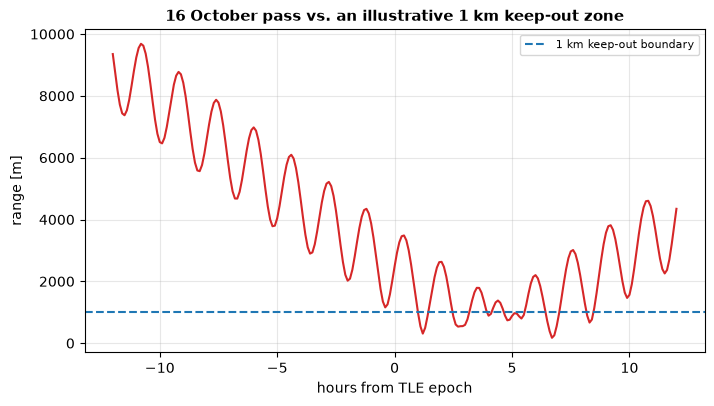

In [9]:
from ios_mission_planner.safety.keepout import KeepOutEllipsoid, check_trajectory

sats = historical_tles["2026-10-16"]
sat_c, sat_i = Satrec.twoline2rv(*sats[68762]), Satrec.twoline2rv(*sats[59103])
jd0, fr0 = jd_from_tle_epoch(sats[59103][0])

hours = np.arange(-12, 12.01, 0.1)
positions = []
for dh in hours:
    jd, fr = jd0, fr0 + dh / 24.0
    ec, rc, vc = sat_c.sgp4(jd, fr)
    ei, ri, vi = sat_i.sgp4(jd, fr)
    positions.append(inertial_to_lvlh(np.array(ri + vi), np.array(rc + vc))[:3] * 1e3)
positions = np.array(positions)

zone = KeepOutEllipsoid(a=1000.0, b=1000.0, c=1000.0)
violated, margin, mask = check_trajectory(positions, zone)
print(f"1 km keep-out zone on 16 Oct: violated={violated}, margin={margin:.3f}, "
      f"minimum range={np.linalg.norm(positions, axis=1).min():.1f} m")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(hours, np.linalg.norm(positions, axis=1), color=COL_NUM)
ax.axhline(zone.a, color=COL_ANA, ls="--", label="1 km keep-out boundary")
ax.set_xlabel("hours from TLE epoch"); ax.set_ylabel("range [m]")
ax.set_title("16 October pass vs. an illustrative 1 km keep-out zone")
ax.legend(fontsize=8)
plt.show()

Yes, by a wide margin: the reconstructed pass spends real time inside even a generous 1 km zone, let alone a tighter one. This project's own `check_trajectory` makes that a one-line, quantitative answer instead of an impression from a headline.

## Summary

Public TLE data, propagated with this project's own relative-motion tools, reconstructs this encounter well enough to match the publicly reported numbers closely: minima of 169 m and 176 m on 16 and 17 October against a reported "2 to 3 km, with moments around 500 m," found only once genuinely historical elements, from COMSPOC Spacebook's free archive, replaced today's. The semi-major-axis signature adds a second, independent line of evidence: small, reversed speed changes on exactly the two days the public reporting describes the satellite shifting position, the same out-and-back shape this project's own two-impulse targeting produces by design. And a keep-out zone check, the same one this project built for its own missions, says plainly that a 1 km zone around ICEYE-X36 would have been violated, for real, not hypothetically.

None of this required anything beyond public data and tools already built for a different purpose, designing this project's own missions rather than reading someone else's. That is itself worth noting: the line between planning a rendezvous and recognizing one from the outside is thinner than it looks.